# Dataset 1: Diabetes
## Algoritmo: K-Nearest Neighbors (KNN) – Clasificación
**Curso:** Machine Learning 
**Objetivo:** predecir si una paciente tiene diabetes (`Outcome`: yes/no) a partir de 8 variables clínicas, **priorizando minimizar los Falsos Negativos** (pacientes diabéticas no detectadas).

**Flujo de trabajo** (técnicas del Capítulo 1: Preprocesamiento + KNN):
1. Limpieza inicial
2. Train / Test estratificado (80 / 20)
3. **Detección de outliers** univariados y multivariados con K-Fold (solo reporte)
4. **Imputación:** MICE vs imputación simple, comparadas con validación cruzada
5. **Balance de clases:** SMOTE y sus variantes, comparadas con validación cruzada
6. **GridSearchCV** de KNN (K, vecinos ponderados, distancia de Minkowski) con `refit = "Recall"`
7. Evaluación final en Test

In [ ]:
# ==================================================
# 0. LIBRERÍAS
# ==================================================
# !pip install imbalanced-learn pingouin

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold, cross_validate
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.covariance import EllipticEnvelope
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

from imblearn.pipeline import Pipeline as ImbPipeline, make_pipeline
from imblearn.over_sampling import SMOTE, BorderlineSMOTE, ADASYN
from imblearn.combine import SMOTETomek, SMOTEENN

import pingouin as pg
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# ==================================================
# 1. DATOS
# ==================================================
df = pd.read_excel("Diabetes.xlsx")

print("Dimensiones del dataset:", df.shape)
df.head()

Dimensiones del dataset: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6.0,148.0,72.0,35.0,NaN,33.6,0.627,50,yes
1,1.0,85.0,66.0,29.0,NaN,26.6,0.351,31,no
2,8.0,183.0,64.0,NaN,NaN,23.3,0.672,32,yes
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21,no
4,NaN,137.0,40.0,35.0,168.0,43.1,2.288,33,yes


## 1.1 Limpieza inicial: ceros biológicamente imposibles
Un valor 0 en `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` o `BMI` es imposible en una persona viva: en realidad es un **dato faltante mal registrado**. Se reemplaza por `NaN`.

In [ ]:
vars_cero_imposible = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Ceros encontrados antes de la limpieza:")
print((df[vars_cero_imposible] == 0).sum())

df[vars_cero_imposible] = df[vars_cero_imposible].replace(0, np.nan)

Ceros encontrados antes de la limpieza:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


### 1.2 Revisión de `Pregnancies`
En este archivo los ceros ya venían como `NaN`, **también en `Pregnancies`**. Pero en `Pregnancies` el 0 **sí es biológicamente posible** (nunca estuvo embarazada):
- el valor mínimo observado es 1 → no existe ningún 0 en el archivo;
- las pacientes con `NaN` son más jóvenes (mediana 25 años vs 30).

Por eso, esos `NaN` corresponden a **0 embarazos** y se recodifican como 0.

In [ ]:
print("Mínimo de Pregnancies:", df["Pregnancies"].min())
print("NaN en Pregnancies:", df["Pregnancies"].isna().sum())
print("\nEdad mediana según si Pregnancies es NaN:")
print(df.groupby(df["Pregnancies"].isna())["Age"].median().rename({False: "Con dato", True: "NaN"}))

df["Pregnancies"] = df["Pregnancies"].fillna(0)

Mínimo de Pregnancies: 1.0
NaN en Pregnancies: 111

Edad mediana según si Pregnancies es NaN:
Pregnancies
Con dato    30.0
NaN         25.0
Name: Age, dtype: float64


In [ ]:
# Variables predictoras y respuesta: 'yes' -> 1 (diabetes), 'no' -> 0
X = df.drop(columns = "Outcome")
y = df["Outcome"].map({"no": 0, "yes": 1}).rename("diabetes")
class_names = ["no", "yes"]

print("Distribución de clases:")
print(pd.DataFrame({"n": y.value_counts(), "%": (y.value_counts(normalize = True) * 100).round(1)}))

print("\nFaltantes por variable:")
print(pd.DataFrame({
    "Faltantes": X.isna().sum(),
    "%": (X.isna().mean() * 100).round(1)
}).sort_values("Faltantes", ascending = False))

Distribución de clases:
            n     %
diabetes           
0         500  65.1
1         268  34.9

Faltantes por variable:
                          Faltantes     %
Insulin                         374  48.7
SkinThickness                   227  29.6
BloodPressure                    35   4.6
BMI                              11   1.4
Glucose                           5   0.7
Pregnancies                       0   0.0
DiabetesPedigreeFunction          0   0.0
Age                               0   0.0


In [ ]:
# ==================================================
# 2. TRAIN / TEST  (¡ANTES de cualquier preprocesamiento!)
# ==================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.20,
    stratify = y,
    random_state = 42
)

print("Train:", X_train.shape, " | Test:", X_test.shape)
print("Proporción clase 1 -> Train: {:.3f} | Test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: (614, 8)  | Test: (154, 8)
Proporción clase 1 -> Train: 0.349 | Test: 0.351


## 3. Identificación de outliers con K-Fold Cross-Validation (solo reporte)
Se aplican los métodos vistos en clase **solo sobre Train** y dentro de cada fold de entrenamiento. Esta sección es **exploratoria**: no se elimina ningún registro.

### 3.1 Normalidad multivariada – Prueba de Henze-Zirkler
**Elliptic Envelope** ajusta una elipse (distancia de Mahalanobis robusta) y por lo tanto **supone normalidad multivariada**. Antes de interpretarlo se verifica ese supuesto.
- H₀: los datos siguen una distribución normal multivariada.
- H₁: no siguen una distribución normal multivariada.

In [ ]:
hz = pg.multivariate_normality(X_train.dropna(), alpha = 0.05)
print("Casos completos:", X_train.dropna().shape[0])
print("Henze-Zirkler: HZ = {:.4f} | p-valor = {:.3e} | ¿Normal? {}".format(hz.hz, hz.pval, hz.normal))

Casos completos: 322
Henze-Zirkler: HZ = 1.8983 | p-valor = 6.380e-237 | ¿Normal? False


**Decisión:** p < 0.05 → se **rechaza H₀**: los datos **no** son normales multivariados. Los resultados de **Elliptic Envelope** se reportan, pero se interpretan **con cautela**; se da más peso a **Isolation Forest** y **LOF**, que no suponen ninguna distribución.

In [ ]:
# =============================================================================
# 3.2 FUNCIONES PARA IDENTIFICAR OUTLIERS
# =============================================================================

# MÉTODOS UNIVARIADOS

def get_outliers_zscore(X, threshold = 3):
    """Identifica outliers usando Z-Score"""
    z_scores = np.abs(stats.zscore(X))
    return np.any(z_scores > threshold, axis = 1)

def get_outliers_iqr(X, multiplier = 1.5):
    """Identifica outliers usando IQR"""
    outlier_mask = np.zeros(X.shape[0], dtype = bool)
    for col in range(X.shape[1]):
        q1 = np.percentile(X[:, col], 25)
        q3 = np.percentile(X[:, col], 75)
        iqr = q3 - q1
        lower = q1 - multiplier * iqr
        upper = q3 + multiplier * iqr
        col_outliers = (X[:, col] < lower) | (X[:, col] > upper)
        outlier_mask = outlier_mask | col_outliers
    return outlier_mask

def get_outliers_mad(X, threshold = 3.5):
    """Identifica outliers usando MAD"""
    outlier_mask = np.zeros(X.shape[0], dtype = bool)
    for col in range(X.shape[1]):
        median = np.median(X[:, col])
        mad = np.median(np.abs(X[:, col] - median))
        if mad > 0:
            robust_z = 0.6745 * (X[:, col] - median) / mad
            col_outliers = np.abs(robust_z) > threshold
            outlier_mask = outlier_mask | col_outliers
    return outlier_mask

# MÉTODOS MULTIVARIADOS

def get_outliers_iforest(X, contamination = 0.05):
    """Identifica outliers usando Isolation Forest"""
    X_scaled = StandardScaler().fit_transform(X)
    detector = IsolationForest(contamination = contamination, random_state = 42)
    return detector.fit_predict(X_scaled) == -1

def get_outliers_lof(X, contamination = 0.05):
    """Identifica outliers usando LOF"""
    X_scaled = StandardScaler().fit_transform(X)
    detector = LocalOutlierFactor(contamination = contamination)
    return detector.fit_predict(X_scaled) == -1

def get_outliers_elliptic(X, contamination = 0.05):
    """Identifica outliers usando Elliptic Envelope"""
    X_scaled = StandardScaler().fit_transform(X)
    detector = EllipticEnvelope(contamination = contamination, random_state = 42)
    return detector.fit_predict(X_scaled) == -1

Estos métodos no aceptan valores faltantes. **Solo para la detección**, en cada fold se imputa con la mediana calculada con ese mismo fold de entrenamiento.

In [ ]:
# =============================================================================
# 3.3 APLICAR K-FOLD CROSS-VALIDATION (sobre Train)
# =============================================================================
kf = KFold(n_splits = 5, shuffle = True, random_state = 42)

results_by_fold = []

for fold, (train_idx, test_idx) in enumerate(kf.split(X_train), 1):
    X_fold = SimpleImputer(strategy = "median").fit_transform(X_train.iloc[train_idx])

    zscore_mask   = get_outliers_zscore(X_fold)
    iqr_mask      = get_outliers_iqr(X_fold)
    mad_mask      = get_outliers_mad(X_fold)
    iforest_mask  = get_outliers_iforest(X_fold)
    lof_mask      = get_outliers_lof(X_fold)
    elliptic_mask = get_outliers_elliptic(X_fold)

    results_by_fold.append({
        "Fold": fold,
        "N° obs": len(X_fold),
        "Z-Score": np.sum(zscore_mask),
        "IQR": np.sum(iqr_mask),
        "MAD": np.sum(mad_mask),
        "IForest": np.sum(iforest_mask),
        "LOF": np.sum(lof_mask),
        "Elliptic": np.sum(elliptic_mask),
        "Todos Uni": np.sum(zscore_mask & iqr_mask & mad_mask),
        "Todos Multi": np.sum(iforest_mask & lof_mask & elliptic_mask),
        "IForest y LOF": np.sum(iforest_mask & lof_mask),
        "Todos": np.sum(zscore_mask & iqr_mask & mad_mask & iforest_mask & lof_mask & elliptic_mask)
    })

tabla_outliers = pd.DataFrame(results_by_fold).set_index("Fold")
tabla_outliers.loc["Promedio"] = tabla_outliers.mean().round(1)
tabla_outliers

,N° obs,Z-Score,IQR,MAD,IForest,LOF,Elliptic,Todos Uni,Todos Multi,IForest y LOF,Todos
Fold,,,,,,,,,,,
1,491.0,34.0,238.0,184.0,25.0,25.0,25.0,33.0,14.0,17.0,11.0
2,491.0,33.0,256.0,248.0,25.0,25.0,25.0,32.0,8.0,12.0,6.0
3,491.0,33.0,236.0,218.0,25.0,25.0,25.0,33.0,10.0,15.0,8.0
4,491.0,31.0,251.0,235.0,25.0,25.0,25.0,28.0,11.0,12.0,9.0
5,492.0,32.0,247.0,239.0,25.0,25.0,25.0,30.0,5.0,13.0,3.0
Promedio,491.2,32.6,245.6,224.8,25.0,25.0,25.0,31.2,9.6,13.8,7.4


In [ ]:
# Mismos métodos aplicados sobre TODO Train: ¿qué observaciones coinciden?
X_train_imp = SimpleImputer(strategy = "median").fit_transform(X_train)

mascaras = pd.DataFrame({
    "Z-Score":  get_outliers_zscore(X_train_imp),
    "IQR":      get_outliers_iqr(X_train_imp),
    "MAD":      get_outliers_mad(X_train_imp),
    "IForest":  get_outliers_iforest(X_train_imp),
    "LOF":      get_outliers_lof(X_train_imp),
    "Elliptic": get_outliers_elliptic(X_train_imp)
}, index = X_train.index)

todos_uni   = mascaras[["Z-Score", "IQR", "MAD"]].all(axis = 1)
todos_multi = mascaras[["IForest", "LOF", "Elliptic"]].all(axis = 1)
todos       = mascaras.all(axis = 1)

resumen = pd.DataFrame({
    "N° obs": [todos_uni.sum(), todos_multi.sum(), todos.sum()],
    "% con diabetes": [round(y_train[m].mean() * 100, 1) for m in [todos_uni, todos_multi, todos]]
}, index = ["Todos los univariados", "Todos los multivariados", "Todos los métodos"])

print(resumen)
print("\nReferencia: % con diabetes en todo Train =", round(y_train.mean() * 100, 1))

                         N° obs  % con diabetes
Todos los univariados        39            53.8
Todos los multivariados      10            70.0
Todos los métodos             7            85.7

Referencia: % con diabetes en todo Train = 34.9


In [ ]:
# Observaciones detectadas por TODOS los métodos
pd.concat([X_train.loc[todos], y_train.loc[todos]], axis = 1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,diabetes
228,4.0,197.0,70.0,39.0,744.0,36.7,2.329,31,0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33,1
45,0.0,180.0,66.0,39.0,NaN,42.0,1.893,25,1
370,3.0,173.0,82.0,48.0,465.0,38.4,2.137,25,1
753,0.0,181.0,88.0,44.0,510.0,43.3,0.222,26,1
579,2.0,197.0,70.0,99.0,NaN,34.7,0.575,62,1
409,1.0,172.0,68.0,49.0,579.0,42.4,0.702,28,1


**Interpretación y decisión:**
- Los métodos univariados detectan muchas más observaciones que los multivariados, porque basta un valor extremo en **una** variable (p. ej. `Insulin` o `DiabetesPedigreeFunction`, muy asimétricas).
- Las observaciones detectadas por **todos los métodos** tienen valores extremos pero **clínicamente posibles** (no son errores de registro) y una proporción de diabéticas mayor que el promedio.
- **Decisión:** los outliers **se conservan**. Eliminarlos haría perder casos de la clase de interés.

## 4. Métodos de imputación con validación cruzada
`Insulin` (≈49 %) y `SkinThickness` (≈30 %) tienen muchos faltantes. Se comparan tres imputadores dentro del mismo pipeline, con un KNN base (K = 5):

| Método | Idea |
|---|---|
| **MICE** (`IterativeImputer` + `BayesianRidge`) | estima cada faltante con una regresión sobre las demás variables, de forma iterativa |
| **Media** (`SimpleImputer`) | reemplaza por la media de la variable |
| **Mediana** (`SimpleImputer`) | reemplaza por la mediana (robusta a outliers) |

El imputador vive **dentro del pipeline**, así que en cada fold se ajusta solo con el fold de entrenamiento.

In [ ]:
# ----- Validación cruzada y métricas -----
validacion = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)
scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def resumen_cv(cv_results):
    """Media y desviación estándar de cada métrica"""
    return {f"{m} (media)": round(cv_results[f"test_{m}"].mean(), 4) for m in scoring_metrics} | \
           {"recall (sd)": round(cv_results["test_recall"].std(), 4)}

def imputador_mice():
    return IterativeImputer(
        estimator = BayesianRidge(),
        max_iter = 30,
        tol = 1e-3,
        random_state = 42
    )

imputadores = {
    "MICE":    imputador_mice(),
    "Media":   SimpleImputer(strategy = "mean"),
    "Mediana": SimpleImputer(strategy = "median")
}

resultados_imp = {}
for nombre, imputador in imputadores.items():
    flujo = make_pipeline(imputador, StandardScaler(), KNeighborsClassifier(n_neighbors = 5))
    cv_res = cross_validate(flujo, X_train, y_train, cv = validacion, scoring = scoring_metrics, n_jobs = -1)
    resultados_imp[nombre] = resumen_cv(cv_res)

tabla_imp = pd.DataFrame(resultados_imp).T
tabla_imp

,accuracy (media),precision (media),recall (media),f1 (media),roc_auc (media),recall (sd)
MICE,0.7556,0.6703,0.6118,0.6377,0.7962,0.0410
Media,0.7426,0.6508,0.5934,0.6172,0.7917,0.0486
Mediana,0.7296,0.6367,0.5654,0.5939,0.7843,0.0558


In [ ]:
mejor_imputacion = tabla_imp["recall (media)"].idxmax()
print("Mejor método de imputación (Recall CV):", mejor_imputacion)

Mejor método de imputación (Recall CV): MICE


**Decisión:** **MICE** obtiene los mejores resultados en **todas** las métricas (Recall, F1, AUC). Tiene sentido: en lugar de asignar el mismo valor a todas las pacientes, estima `Insulin` y `SkinThickness` a partir de variables relacionadas (`Glucose`, `BMI`, `Age`…). Se usa MICE en el resto del análisis.

## 5. Balance de clases: SMOTE y sus variantes
Las clases están desbalanceadas (≈65 % / 35 %). Se compara el modelo **base (sin balanceo)** con **SMOTE y sus variantes** vistas en clase, todas con MICE y un KNN base (K = 5):

| Método | Idea |
|---|---|
| **SMOTE** | crea casos sintéticos de la clase minoritaria interpolando entre vecinos |
| **Borderline-SMOTE** | genera casos sintéticos solo cerca de la frontera entre clases |
| **ADASYN** | genera más casos donde la clase minoritaria es más difícil de aprender |
| **SMOTE + Tomek Links** | SMOTE y luego elimina pares de puntos de clases distintas muy cercanos |
| **SMOTE + ENN** | SMOTE y luego elimina las observaciones mal clasificadas por sus vecinos (limpieza más agresiva) |

*Nota:* los **pesos de clase** no se pueden usar porque `KNeighborsClassifier` no tiene el parámetro `class_weight`.

El método de balanceo va **dentro del pipeline** (después de imputar y escalar) y se aplica **solo al entrenar**; los folds de validación y el Test se evalúan siempre con datos reales.

In [ ]:
metodos_balance = {
    "Base (sin balanceo)": None,
    "SMOTE":            SMOTE(random_state = 42),
    "Borderline-SMOTE": BorderlineSMOTE(random_state = 42),
    "ADASYN":           ADASYN(random_state = 42),
    "SMOTE + Tomek":    SMOTETomek(random_state = 42),
    "SMOTE + ENN":      SMOTEENN(random_state = 42)
}

resultados_bal = {}
for nombre, metodo in metodos_balance.items():
    pasos = [imputador_mice(), StandardScaler()] + ([metodo] if metodo is not None else []) + \
            [KNeighborsClassifier(n_neighbors = 5)]
    flujo = make_pipeline(*pasos)
    cv_res = cross_validate(flujo, X_train, y_train, cv = validacion, scoring = scoring_metrics, n_jobs = -1)
    resultados_bal[nombre] = resumen_cv(cv_res)

tabla_bal = pd.DataFrame(resultados_bal).T
tabla_bal

,accuracy (media),precision (media),recall (media),f1 (media),roc_auc (media),recall (sd)
Base (sin balanceo),0.7556,0.6703,0.6118,0.6377,0.7962,0.0410
SMOTE,0.7262,0.5877,0.7473,0.6573,0.7925,0.0477
Borderline-SMOTE,0.7002,0.5536,0.7754,0.6452,0.7723,0.0339
ADASYN,0.6953,0.5466,0.7659,0.6376,0.7713,0.0517
SMOTE + Tomek,0.7181,0.5773,0.7426,0.6490,0.7946,0.0390
SMOTE + ENN,0.7361,0.5926,0.8179,0.6853,0.8075,0.0261


In [ ]:
variantes_smote = tabla_bal.drop(index = "Base (sin balanceo)")
mejor_balance = variantes_smote["recall (media)"].idxmax()
print("Mejor variante de SMOTE (Recall CV):", mejor_balance)

Mejor variante de SMOTE (Recall CV): SMOTE + ENN


**Decisión: SMOTE + ENN.**
- Todas las variantes de SMOTE suben mucho el Recall frente al modelo base, que deja escapar a casi 4 de cada 10 diabéticas.
- **SMOTE + ENN** es la mejor variante en **Recall, F1 y AUC a la vez**, y además tiene la **menor desviación** del Recall entre folds (más estable).
- **¿Por qué funciona mejor con KNN?** Después de crear los casos sintéticos, ENN **elimina las observaciones cuyos vecinos son mayoritariamente de la otra clase**. Así limpia la zona de solapamiento entre diabéticas y no diabéticas, y KNN, que decide por vecindad, encuentra vecinos más "puros".
- Borderline-SMOTE y ADASYN suben el Recall pero bajan la Precision y el AUC: generan casos justo en la zona difícil, lo que añade ruido a KNN.

## 6. Optimización de hiperparámetros de KNN
Pipeline final: `MICE → StandardScaler → SMOTE + ENN → KNN`

Se buscan con GridSearchCV (5 folds estratificados):
- **K** (número de vecinos).
- **Vecinos ponderados** (visto en clase): `uniform` (todos los vecinos votan igual) vs `inverso`, donde cada vecino pesa $w_i = \frac{1}{d(x_0, x_i) + \varepsilon}$ y los más cercanos influyen más.
- **Distancia de Minkowski** $d_p(x_i, x_j) = \left(\sum_k |x_{ik} - x_{jk}|^p\right)^{1/p}$: p = 1 es Manhattan y p = 2 es Euclidiana. Se prueban p = 1, 1.5, 2, 3 y 4.

### Criterio de selección
Se prioriza el **Recall** (minimizar Falsos Negativos), pero muchas combinaciones quedan **empatadas** en Recall CV, con diferencias de milésimas, mucho menores que la desviación entre folds. Elegir por esa diferencia sería elegir por ruido. Por eso, entre las combinaciones con Recall a menos de **0.005** del máximo, se elige la de **mayor F1**: el mismo Recall con **menos Falsos Positivos**.

In [ ]:
# Peso de vecinos ponderados (fórmula de clase: w = 1 / (d + ε))
EPS = 1e-6

def inverso(distancias):
    return 1 / (distancias + EPS)

pipeline_knn = ImbPipeline([
    ("imputer", imputador_mice()),
    ("scaler", StandardScaler()),
    ("balance", SMOTEENN(random_state = 42)),
    ("knn", KNeighborsClassifier(metric = "minkowski"))
])

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 25, 31, 41, 51, 61],
    "knn__weights": ["uniform", inverso],
    "knn__p": [1, 1.5, 2, 3, 4]
}

scoring = {
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Máximo Recall; si hay empate (diferencia < 0.005), se desempata con el mayor F1
TOLERANCIA = 0.005

def recall_con_desempate_f1(cv_results):
    recall = np.asarray(cv_results["mean_test_Recall"])
    f1 = np.asarray(cv_results["mean_test_F1"])
    candidatos = np.where(recall >= recall.max() - TOLERANCIA)[0]
    return candidatos[np.argmax(f1[candidatos])]

grid_search = GridSearchCV(
    pipeline_knn,
    param_grid = param_grid,
    cv = validacion,
    scoring = scoring,
    refit = recall_con_desempate_f1,
    n_jobs = -1
)

grid_search.fit(X_train, y_train);

In [ ]:
# Mejor modelo
i = grid_search.best_index_
r = grid_search.cv_results_
pesos = grid_search.best_params_["knn__weights"]

mejor = pd.DataFrame({
    "K": [grid_search.best_params_["knn__n_neighbors"]],
    "Pesos": [pesos if isinstance(pesos, str) else "inverso (1/d)"],
    "p (Minkowski)": [grid_search.best_params_["knn__p"]],
    "Recall CV": [round(r["mean_test_Recall"][i], 4)],
    "Recall sd": [round(r["std_test_Recall"][i], 4)],
    "F1 CV": [round(r["mean_test_F1"][i], 4)],
    "AUC CV": [round(r["mean_test_ROC_AUC"][i], 4)]
}, index = ["Mejor modelo"])
mejor

,K,Pesos,p (Minkowski),Recall CV,Recall sd,F1 CV,AUC CV
Mejor modelo,11,inverso (1/d),3,0.8458,0.0234,0.6947,0.8271


**Mejor modelo: KNN ponderado con K = 11 y distancia de Minkowski p = 3.**
- Con la validación cruzada detecta en promedio al **≈85 % de las diabéticas** (Recall CV = 0.846).
- **K = 11** es un valor intermedio: con K pequeño el modelo sobreajusta (alta varianza) y con K muy grande pierde la estructura local (alto sesgo).
- **Pesos inversos a la distancia:** con el mismo Recall que el KNN estándar, logra mayor F1, porque los vecinos más cercanos (más parecidos a la paciente) pesan más en la decisión.
- **p = 3:** una distancia intermedia entre la Euclidiana (p = 2) y la de Chebyshev (p → ∞), que da más peso a las variables donde dos pacientes difieren más.

In [ ]:
# ==================================================
# 7. EVALUACIÓN EN TEST (una sola vez)
# ==================================================
mejor_modelo = grid_search.best_estimator_

y_pred = mejor_modelo.predict(X_test)
y_prob = mejor_modelo.predict_proba(X_test)[:, 1]

metricas_test = pd.DataFrame({
    "Valor": [
        recall_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        accuracy_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
}, index = ["Recall", "Precision", "F1-Score", "Accuracy", "AUC-ROC"]).round(4)

print("Métricas en Test (clase positiva = diabetes):")
print(metricas_test)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names = class_names))

Métricas en Test (clase positiva = diabetes):
            Valor
Recall     0.8148
Precision  0.5432
F1-Score   0.6519
Accuracy   0.6948
AUC-ROC    0.7759

Reporte de clasificación:
              precision    recall  f1-score   support

          no       0.86      0.63      0.73       100
         yes       0.54      0.81      0.65        54

    accuracy                           0.69       154
   macro avg       0.70      0.72      0.69       154
weighted avg       0.75      0.69      0.70       154



          Pred no  Pred yes
Real no        63        37
Real yes       10        44

Verdaderos Negativos (TN): 63
Falsos Positivos   (FP): 37  -> sanas clasificadas como diabéticas
Falsos Negativos   (FN): 10  -> diabéticas NO detectadas
Verdaderos Positivos (TP): 44


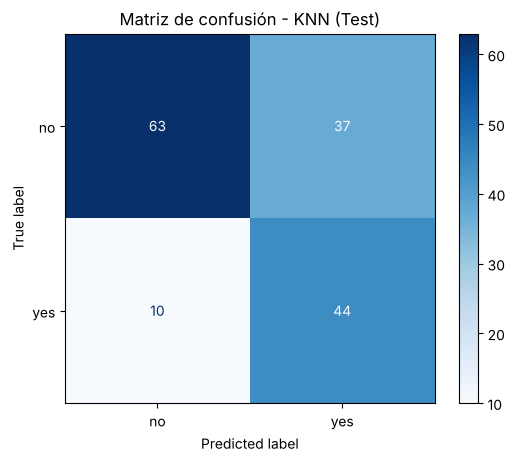

In [ ]:
# Matriz de confusión completa
cm = confusion_matrix(y_test, y_pred)
TN, FP, FN, TP = cm.ravel()

print(pd.DataFrame(cm, index = ["Real no", "Real yes"], columns = ["Pred no", "Pred yes"]))
print("\nVerdaderos Negativos (TN):", TN)
print("Falsos Positivos   (FP):", FP, " -> sanas clasificadas como diabéticas")
print("Falsos Negativos   (FN):", FN, " -> diabéticas NO detectadas")
print("Verdaderos Positivos (TP):", TP)

ConfusionMatrixDisplay(cm, display_labels = class_names).plot(cmap = "Blues")
plt.title("Matriz de confusión - KNN (Test)")
plt.show()

## 8. Conclusiones
- **Limpieza:** los ceros imposibles se trataron como faltantes y los `NaN` de `Pregnancies` se recodificaron como 0 embarazos.
- **Outliers:** se aplicaron los 6 métodos de clase (Z-Score, IQR, MAD, Isolation Forest, LOF, Elliptic Envelope) con K-Fold. Como Henze-Zirkler rechaza la normalidad multivariada, Elliptic Envelope se interpretó con cautela. Los atípicos son clínicamente plausibles y **se conservaron**.
- **Imputación:** MICE superó a la imputación simple (media y mediana) en todas las métricas.
- **Balance:** SMOTE + ENN fue la mejor variante de SMOTE en Recall, F1 y AUC.
- **KNN:** K, los pesos (estándar vs ponderado) y el parámetro p de Minkowski se eligieron con GridSearchCV (5 folds estratificados) priorizando el **Recall** y desempatando por F1.
- **Sin data leakage:** imputación, escalado y balanceo viven dentro del pipeline y se ajustan solo con el fold de entrenamiento; el Test se usó una sola vez.